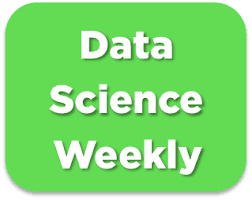

# Import libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import r2_score
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import cross_val_score

import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings(
    "ignore", category=DeprecationWarning
)  # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from IPython.display import display

# Read file with labels

In [2]:
df = pd.read_csv("walmart_sales.csv")

# Preprocessing

## preprocessing pandas

In [3]:
df.columns = df.columns.str.lower()
print(df.columns)

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')


### Missing values

In [4]:
print('Missing values treatment...')
cols = ['weekly_sales', 'date']
df = df.dropna(subset=cols) # drop lines where target values is missing. 
categories = ['store', 'holiday_flag']

df[categories] = df[categories].astype('Int64') # convert categories in integers, avoid error "Cannot convert non-finite values".
print(df.dtypes)

Missing values treatment...
store             Int64
date                str
weekly_sales    float64
holiday_flag      Int64
temperature     float64
fuel_price      float64
cpi             float64
unemployment    float64
dtype: object


### Convert data

In [5]:
# Conversion des dates au format date time
type('date')
df['date'] = pd.to_datetime(df['date'], format = "%d-%m-%Y")
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.dayofweek
print(df['weekday'].value_counts(dropna=False))

weekday
4    118
Name: count, dtype: int64


In [6]:
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)
print(df[categories + ['date']].dtypes)

store                    Int64
holiday_flag             Int64
date            datetime64[us]
dtype: object


In [7]:
df=df.drop('date', axis=1)

In [8]:
df.head(1)

,store,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,day,weekday
0,6,1572117.54,<NA>,59.61,3.04,214.78,6.86,2011,2,18,4


### mask outlyers

In [9]:
mean = df['unemployment'].mean()
sigma = df['unemployment'].std()

mask = df['unemployment'].between(mean - 3 * sigma, mean + 3 * sigma)
df = df[mask]
print(df.shape)

(102, 11)


# Baseline model

## preprocessing en sklearn

### Multivariate linear regression

#### Separate target variable Y from features X

In [10]:
# Separate target variable Y from features X

print("Separating labels from features...")
target = 'weekly_sales'

y = df.loc[:, target]# or df.iloc[:, -1] # or  df.loc[:, df.columns == target]
X = df.drop(target, axis=1) # or df.iloc[:, 0:-1]  # All columns are kept, except the target
# or df.loc[:, df.columns != target]
print("...Done.")

print("y : ")
print(y.head())
print()
print("X : ")
print(X.head())

Separating labels from features...
...Done.
y : 
0    1572117.54
1    1807545.43
4    1644470.66
5    1857533.70
6     695396.19
Name: weekly_sales, dtype: float64

X : 
   store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
0      6          <NA>        59.61        3.04  214.78          6.86  2011   
1     13             0        42.38        3.44  128.62          7.47  2011   
4      6             0        78.89        2.76  212.41          7.09  2010   
5      4             0          NaN        2.76  126.16          7.90  2010   
6     15             0        69.80        4.07  134.86          7.66  2011   

   month  day  weekday  
0      2   18        4  
1      3   25        4  
4      5   28        4  
5      5   28        4  
6      6    3        4  


In [11]:
'''# Automatically detect names of numeric/categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Found numeric features ", numeric_features)
print("Found categorical features ", categorical_features)'''

'# Automatically detect names of numeric/categorical columns\nnumeric_features = X.select_dtypes(include="number").columns.tolist()\ncategorical_features = X.select_dtypes(exclude="number").columns.tolist()\n\nprint("Found numeric features ", numeric_features)\nprint("Found categorical features ", categorical_features)'

In [12]:
numeric_features = ['temperature', 'fuel_price', 'cpi', 'unemployment', 'year', 'month', 'day', 'weekday']
categorical_features = ['store', 'holiday_flag']

Remember to treat year, 'month', 'day', 'weekday' as numeric features (cf instructions)

#### Divide dataset train set & test set 

We apply different transformations to the features, depending on their types. Numeric columns will be standardized whereas categorical columns will be one-hot-encoded. As regards missing values imputation, it can apply to every column, but different rules may be used. 

In [13]:
# Divide dataset Train set & Test set
print("Dividing into train and test sets...")
# WARNING : don't forget stratify=Y for classification problems
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



We'll use simple imputer because we don't have any missing values. num_imputer = SimpleImputer(strategy="median")

We normalize numeric colomns to scale them down.

#### pipelines

In [14]:
print("Preprocessing X_train...")
print(X_train.head())
print()

# categoric

cat_transformer = Pipeline(steps=[
    ('cat_imputer', SimpleImputer(strategy="most_frequent")),
    ('catEncoder', OneHotEncoder(drop='first'))
])
# numerical

num_transformer = Pipeline(steps=[
    ('num_imputer', SimpleImputer(strategy="median")),
    ('scaler', StandardScaler())
])

Preprocessing X_train...
     store  holiday_flag  temperature  fuel_price     cpi  unemployment  year  \
67       3             0        45.71        2.57  214.42          7.37  2010   
28      17             0        45.22        2.92  126.56          6.64  2010   
98      10             0        90.32         NaN  126.13          9.52  2010   
55      13             0        63.60        3.65  129.52          6.88  2011   
143      3             0        78.53        2.70  214.50          7.34  2010   

     month  day  weekday  
67       2    5        4  
28       4   16        4  
98       6   25        4  
55       9   23        4  
143      6    4        4  



In [15]:
#### pipeline global
print("Encoding categorical features and standardizing numerical features...")

preprocessor = ColumnTransformer(transformers=[
    ('cat_transformer', cat_transformer, categorical_features),
    ('num_transformer', num_transformer, numeric_features)
])

# Preprocessings on train set
print("Preprocessing sur le train set...")
X_train = preprocessor.fit_transform(X_train)
print('...Terminé.')
X_train[0:5] # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()


Encoding categorical features and standardizing numerical features...
Preprocessing sur le train set...
...Terminé.



Nous n'utilisons pas labelEncoder sur y_test car les labels sont déjà convertis sur converted

#### Test pipeline

In [16]:
# Preprocessings sur le test set
print("Preprocessing on test set...")
X_test = preprocessor.transform(X_test) # Don't fit again !! The test set is used for validating decisions
# we made based on the training set, therefore we can only apply transformations that were parametered using the training set.
# Otherwise this creates what is called a leak from the test set which will introduce a bias in all your results.
print('...Done.')
X_test[:5, :] # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore

Preprocessing on test set...
...Done.


array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00, -5.60762239e-02,  2.11054118e-02,
         9.31889073e-01, -1.09461824e+00,  1.77821690e-01,
         1.46509567e+00, -7.39593987e-01,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         1.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00, -6.89343436e-01,  1.30691204e-01,
         8.31168414e-01, -1.09461824e+00, -1.02247472e+

#### Train model

In [17]:

from sklearn.linear_model import LinearRegression

print("Train model...")
baseline = LinearRegression() # 
baseline.fit(X_train, y_train)
print("...Done.")

Train model...
...Done.


#### Performance evaluation

#### Predictions

In [18]:
# Predictions on training set
print("Predictions on training set...")
y_train_pred = baseline.predict(X_train)
print("...Done.")
print(y_train_pred)
print()

Predictions on training set...
...Done.
[ 503338.69067573  765695.84568536 1650963.4406444  1970135.69423092
  434379.75674651  231843.1895169   349140.68176514  423350.96062187
 1565772.04367999  135871.25426956 1517857.07080007 1354917.85841689
 2219062.42548716  947940.14630438  501088.25132788 2097346.406797
 1389454.16671922 2003058.1194779  1890223.80379964 1168832.721223
 2032321.91729769 1542379.91050061 1149571.21126039 1939754.90528651
 2355041.94189223  306038.80817389  911921.25431464  931071.05060753
 2085251.52225383 1939673.12288087 1973824.77406908 2027580.75426387
  515107.68436469 2009423.81369431 1420024.07807169 1546387.39496891
  501879.5920355  1757242.51        800703.29939248 1562128.21657738
  232024.76945602  573372.35729334 1518524.76922962  429451.50128645
 1485715.84781982  442605.39726112 2008903.4651883  1613441.33053443
  334001.15455188  602741.81943899  485322.20273748  475179.93788598
 2057324.9440646   570611.23       2059766.02316566  477943.725713


In [20]:
# Predictions on test set
print("Predictions on test set...")
y_test_pred = baseline.predict(X_test)
print("...Done.")
print(y_test_pred)
print()

Predictions on test set...
...Done.
[ 490065.79905489  885282.53824819 1977569.56581426 2120649.13190704
 2033210.93430129 2123212.15508857 1976003.32882433  849364.9038383
  894903.84730971 1610390.43435905 1495163.96000245  970944.79752096
  399200.07217087  468525.32089374  870006.63207377  594027.52346984
 2068979.19411468  421562.03271656 2187041.76350737 1419579.26091872
 2045239.61164743]



In [21]:
# Print R^2 scores
print("R2 score on training set : ", r2_score(y_train, y_train_pred))
print("R2 score on test set : ", r2_score(y_test, y_test_pred))

R2 score on training set :  0.9762514386075658
R2 score on test set :  0.9490658189348575


The baseline model overfits.

Interpreting the models coefficients

In [22]:
baseline.coef_

array([ 3.22446149e+05, -1.24687411e+06,  7.99638217e+05, -1.32644419e+06,
        1.07603103e+01, -1.03714266e+06, -7.97077095e+05, -1.21792070e+06,
        6.54554145e+05,  2.54226623e+05,  6.71039357e+05,  6.34753870e+05,
       -6.92837573e+05, -1.08961613e+06, -6.24546376e+05, -2.11635938e+05,
        1.55491714e+05,  3.67568715e+05, -1.45439726e+05, -6.88931342e+04,
       -4.67604278e+04,  1.41395214e+05, -4.94861799e+04,  1.50400742e+04,
        5.15537234e+04, -5.07306558e+04,  0.00000000e+00])

In [23]:
column_names = []
for name, pipeline, features_list in preprocessor.transformers_: # loop over pipelines
    if name == 'num_transformer': # if pipeline is for numeric variables
        features = features_list # just get the names of columns to which it has been applied
    else: # if pipeline is for categorical variables
        features = pipeline.named_steps['catEncoder'].get_feature_names_out() # get output columns names from OneHotEncoder
    column_names.extend(features) # concatenate features names

print("Names of columns corresponding to each coefficient: ", column_names)

Names of columns corresponding to each coefficient:  ['x0_2.0', 'x0_3.0', 'x0_4.0', 'x0_5.0', 'x0_6.0', 'x0_7.0', 'x0_8.0', 'x0_9.0', 'x0_10.0', 'x0_11.0', 'x0_13.0', 'x0_14.0', 'x0_15.0', 'x0_16.0', 'x0_17.0', 'x0_18.0', 'x0_19.0', 'x0_20.0', 'x1_1.0', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'year', 'month', 'day', 'weekday']


In [24]:
# Create a pandas DataFrame
coefs = pd.DataFrame(index = column_names, data = baseline.coef_.transpose(), columns=["coefficients"])
coefs

,coefficients
x0_2.0,3.224461e+05
x0_3.0,-1.246874e+06
x0_4.0,7.996382e+05
x0_5.0,-1.326444e+06
x0_6.0,1.076031e+01
x0_7.0,-1.037143e+06
x0_8.0,-7.970771e+05
x0_9.0,-1.217921e+06
x0_10.0,6.545541e+05
x0_11.0,2.542266e+05


In [25]:
# Compute abs() and sort values
feature_importance = abs(coefs).sort_values(by = 'coefficients')
feature_importance

,coefficients
weekday,0.000000e+00
x0_6.0,1.076031e+01
year,1.504007e+04
fuel_price,4.676043e+04
unemployment,4.948618e+04
day,5.073066e+04
month,5.155372e+04
temperature,6.889313e+04
cpi,1.413952e+05
x1_1.0,1.454397e+05


In [26]:
# Plot coefficients
fig = px.bar(feature_importance, orientation = 'h')
fig.update_layout(showlegend = False,
                  margin = {'l': 120} # to avoid cropping of column names
                 )
fig.show()

In [ ]:
'''import matplotlib.pyplot as plt

plt.scatter(y_test, y_test_pred)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

In [ ]:
'''plt.scatter(y_test, y_test_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()'''

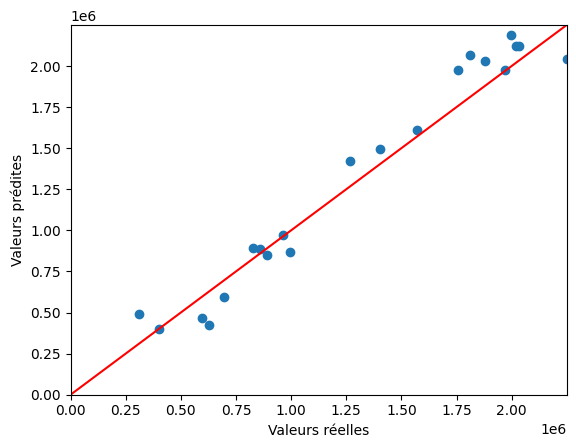

In [27]:
lim_max = max(y_test.max(), y_test_pred.max())

plt.scatter(y_test, y_test_pred)
plt.plot([0, lim_max], [0, lim_max], color="red")
plt.xlim(0, lim_max)
plt.ylim(0, lim_max)
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.show()

In [ ]:
'''plt.scatter(y_test, y_test_pred)
plt.xlim(0)
plt.ylim(0)
plt.show()'''